# Exploratory Data Analysis (EDA)

## Objectives

The aim of this exploratory data analysis is to understand the structure, distribution, and characteristics of the processed MIMIC-III admission-level dataset before applying machine learning models.

The EDA will:

- Examine the distribution of the target variable, `hospital_expire_flag`, and assess the degree of class imbalance.
- Explore the demographic characteristics of the admissions, including age and gender.
- Investigate admission characteristics such as admission type and admission location.
- Examine the distributions and ranges of the selected laboratory measurements recorded within the first 24 hours of admission.
- Assess missing values and identify patterns of missingness that may be relevant to modelling.
- Explore the distribution of the engineered diagnosis features, including primary diagnosis category and number of recorded diagnoses.
- Investigate relationships between individual predictors and in-hospital mortality.
- Identify potential outliers, unusual observations, and data-quality issues that may require further consideration.
- Use the findings from the EDA to inform subsequent preprocessing, feature selection, and machine learning decisions.

The analysis will focus on identifying patterns and relationships within the dataset rather than making causal or clinical claims.



## Importing and inspecting dataset

In [1]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt 

pd.set_option("display.max_columns", None)

In [2]:
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

DATA_DIR = (
    PROJECT_ROOT
    / "data"
    / "raw"
    / "mimic-iii-clinical-database-demo-1.4"
    / "mimic-iii-clinical-database-demo-1.4"
)

print(DATA_DIR)
print(DATA_DIR.exists())

/Users/tmali/Documents/Documents/MSc Healthcare Data Prep/Project - Predictive Health Analytics & Machine Learning with Python/data/raw/mimic-iii-clinical-database-demo-1.4/mimic-iii-clinical-database-demo-1.4
True


In [3]:
labevents = pd.read_csv(DATA_DIR / "LABEVENTS.csv")
admissions = pd.read_csv(DATA_DIR / "ADMISSIONS.csv")
patients = pd.read_csv(DATA_DIR / "PATIENTS.csv")
dlabitems = pd.read_csv(DATA_DIR / "D_LABITEMS.csv")
diagnoses = pd.read_csv(DATA_DIR / "DIAGNOSES_ICD.csv")
icd_dictionary = pd.read_csv(DATA_DIR / "D_ICD_DIAGNOSES.csv")

In [4]:
final_data = pd.read_csv("../data/processed/final_data.csv")

In [5]:
final_data.shape

(129, 36)

In [6]:
final_data.head()

,row_id,subject_id,hadm_id,admittime,dischtime,deathtime,admission_type,admission_location,discharge_location,insurance,language,religion,marital_status,ethnicity,edregtime,edouttime,diagnosis,hospital_expire_flag,has_chartevents_data,bicarbonate,calcium,creatinine,glucose,magnesium,potassium,sodium,urea_nitrogen,haematocrit,haemoglobin,platelet_count,rdw,white_blood_cells,age_at_admission,gender,diagnosis_category_model,num_diagnoses
0,12258,10006,142345,2164-10-23 21:09:00,2164-11-01 17:15:00,NaN,EMERGENCY,EMERGENCY ROOM ADMIT,HOME HEALTH CARE,Medicare,NaN,CATHOLIC,SEPARATED,BLACK/AFRICAN AMERICAN,2164-10-23 16:43:00,2164-10-23 23:00:00,SEPSIS,0,1,31.0,8.5,3.5,84.0,1.4,4.4,139.0,11.0,36.9,11.7,106.0,19.8,4.6,70.633812,F,Injury_poisoning_other,21
1,12263,10011,105331,2126-08-14 22:32:00,2126-08-28 18:59:00,2126-08-28 18:59:00,EMERGENCY,TRANSFER FROM HOSP/EXTRAM,DEAD/EXPIRED,Private,NaN,CATHOLIC,SINGLE,UNKNOWN/NOT SPECIFIED,NaN,NaN,HEPATITIS B,1,1,23.0,8.5,0.7,79.0,1.8,5.9,136.0,3.0,33.9,11.6,299.0,18.9,10.6,36.188912,F,Digestive,6
2,12265,10013,165520,2125-10-04 23:36:00,2125-10-07 15:13:00,2125-10-07 15:13:00,EMERGENCY,TRANSFER FROM HOSP/EXTRAM,DEAD/EXPIRED,Medicare,NaN,CATHOLIC,NaN,UNKNOWN/NOT SPECIFIED,NaN,NaN,SEPSIS,1,1,29.0,9.0,1.7,134.0,1.3,4.1,138.0,32.0,28.1,8.8,213.0,14.3,13.8,87.082820,F,Infectious,9
3,12269,10017,199207,2149-05-26 17:19:00,2149-06-03 18:42:00,NaN,EMERGENCY,EMERGENCY ROOM ADMIT,SNF,Medicare,NaN,CATHOLIC,DIVORCED,WHITE,2149-05-26 12:08:00,2149-05-26 19:45:00,HUMERAL FRACTURE,0,1,26.0,8.7,0.5,221.0,2.0,4.0,139.0,12.0,30.5,10.9,303.0,12.7,17.8,73.675565,F,Injury_poisoning_other,14
4,12270,10019,177759,2163-05-14 20:43:00,2163-05-15 12:00:00,2163-05-15 12:00:00,EMERGENCY,TRANSFER FROM HOSP/EXTRAM,DEAD/EXPIRED,Medicare,NaN,CATHOLIC,DIVORCED,WHITE,NaN,NaN,ALCOHOLIC HEPATITIS,1,1,12.0,8.2,4.0,279.0,1.9,5.2,136.0,31.0,31.5,12.5,85.0,17.2,6.8,48.898015,M,Infectious,14


In [7]:
final_data["hospital_expire_flag"].value_counts()

hospital_expire_flag
0    89
1    40
Name: count, dtype: int64

In [8]:
final_data["hospital_expire_flag"].value_counts(normalize=True)

hospital_expire_flag
0    0.689922
1    0.310078
Name: proportion, dtype: float64

## Creating a visualisation of the dataset

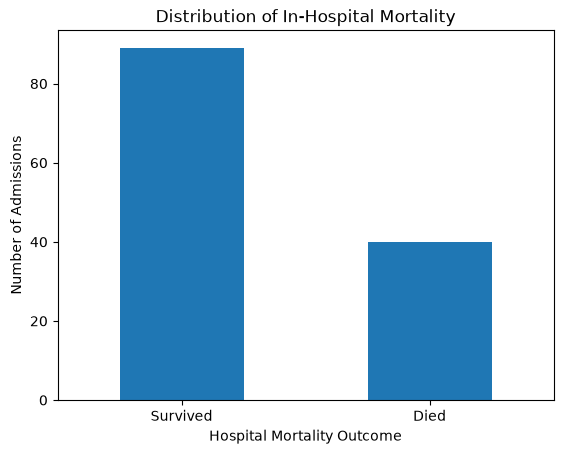

In [9]:
outcome_counts = final_data["hospital_expire_flag"].value_counts()

outcome_counts.plot(kind="bar")

plt.title("Distribution of In-Hospital Mortality")
plt.xlabel("Hospital Mortality Outcome")
plt.ylabel("Number of Admissions")
plt.xticks(
    ticks=[0,1],
    labels=["Survived", "Died"],
    rotation = 0 
)

plt.show()

In [10]:
final_data["age_at_admission"].describe()

count    129.000000
mean      70.307552
std       16.381486
min       17.190965
25%       63.715264
50%       72.728268
75%       82.989733
max       90.000000
Name: age_at_admission, dtype: float64

### Observation

The dataset contains 129 hospital admissions, of which 89 (69.0%) resulted in survival to hospital discharge and 40 (31.0%) resulted in in-hospital death.

This indicates a moderate class imbalance, with surviving admissions representing the majority class. A baseline model that predicted survival for every admission would achieve approximately 69% accuracy but would identify none of the admissions resulting in death.

Therefore, accuracy alone will not be sufficient to evaluate the mortality prediction models. Metrics such as sensitivity (recall), specificity, precision, F1-score, and ROC-AUC will also be considered.

## Visualising age range

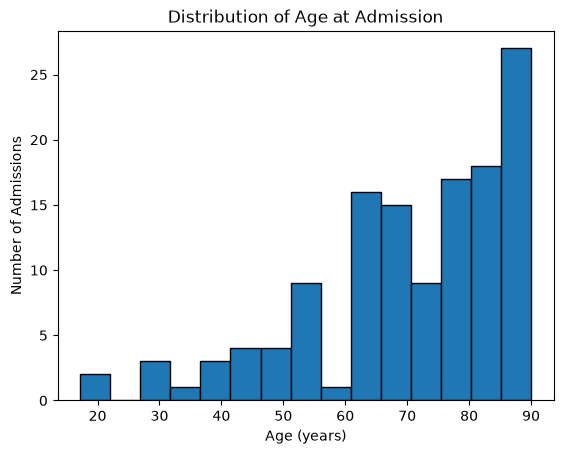

In [11]:
final_data["age_at_admission"].plot(
    kind="hist",
    bins=15,
    edgecolor="black"
)

plt.title("Distribution of Age at Admission")
plt.xlabel("Age (years)")
plt.ylabel("Number of Admissions")

plt.show()

In [12]:
final_data[
    final_data["age_at_admission"] < 40
]["age_at_admission"].sort_values()

54    17.190965
38    19.986311
50    27.014374
34    27.871321
25    29.322382
1     36.188912
Name: age_at_admission, dtype: float64

### Observation 
 
Admissions were predominantly among older adults, with relatively few younger patients. The distribution is concentrated toward the upper end of the age range, with a notable concentration at 90 years resulting from MIMIC-III's age de-identification procedure.

There are relatively few admissions among younger adults, including a sparse region between approximately 20 and 27 years. Given the small sample size of 129 admissions, these gaps are unlikely to be meaningful and should not be interpreted as representative of the wider hospital population.

## Comparing mortality outcomes

In [13]:
final_data.groupby("hospital_expire_flag")["age_at_admission"].describe()

,count,mean,std,min,25%,50%,75%,max
hospital_expire_flag,,,,,,,,
0,89.0,70.300241,14.259057,17.190965,63.715264,72.539357,81.445585,90.0
1,40.0,70.323819,20.541987,19.986311,62.543463,79.448323,86.912389,90.0


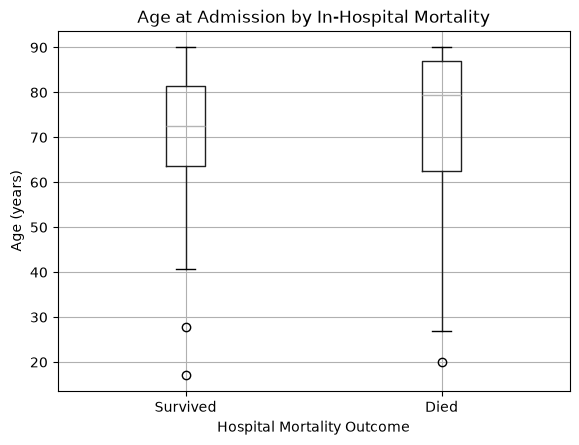

In [14]:
final_data.boxplot(
    column="age_at_admission",
    by="hospital_expire_flag"
)

plt.title("Age at Admission by In-Hospital Mortality")
plt.suptitle("")
plt.xlabel("Hospital Mortality Outcome")
plt.ylabel("Age (years)")
plt.xticks(
    ticks=[1, 2],
    labels=["Survived", "Died"]
)

plt.show()

### Observation

The median age at admission was higher among admissions resulting in in-hospital death (79.4 years) than among surviving admissions (72.5 years). The middle 50% of the mortality group also extended to higher ages, although the two distributions showed substantial overlap.

This suggests that age may be associated with in-hospital mortality in this sample, but age alone does not clearly distinguish between survivors and non-survivors. The mortality group also showed greater variability in age.

Several younger admissions appear as potential outliers relative to the main age distribution. Given the small sample size, these observations were retained rather than removed without evidence of a data-quality problem.

## Investigating admissions characteristics: 

### Gender:

In [15]:
final_data.groupby("gender")["hospital_expire_flag"].agg(
    ["count", "sum", "mean"]
)

,count,sum,mean
gender,,,
F,59,21,0.355932
M,70,19,0.271429


#### Observation

Female admissions had a higher observed in-hospital mortality rate than male admissions in this sample (35.6% vs. 27.1%). However, the relatively small sample size and limited number of deaths within each group make this difference uncertain.

Therefore, gender will be retained as a potential predictor for modelling, but the observed difference should not be interpreted as evidence that female patients have a higher underlying mortality risk. The relationship between gender and mortality will be assessed alongside other predictors in the machine learning models.

### Admission type:

In [16]:
final_data["admission_type"].value_counts()

admission_type
EMERGENCY    119
ELECTIVE       8
URGENT         2
Name: count, dtype: int64

In [17]:
final_data.groupby("admission_type")["hospital_expire_flag"].agg(
    ["count", "sum", "mean"]
)

,count,sum,mean
admission_type,,,
ELECTIVE,8,0,0.000000
EMERGENCY,119,39,0.327731
URGENT,2,1,0.500000


#### Observation

Emergency admissions accounted for 119 of the 129 admissions (92.2%) in the dataset. The observed mortality rate among emergency admissions was 32.8%.

Elective and urgent admissions were substantially less common, with only 8 and 2 admissions respectively. Although no elective admissions and one urgent admission resulted in death, the small sample sizes make these mortality rates unreliable for comparison with emergency admissions.

The strong predominance of emergency admissions limits the ability to draw meaningful conclusions about differences in mortality between admission types. Admission type will nevertheless be retained as a potential predictor for modelling.

### Admission location: 

In [18]:
final_data["admission_location"].value_counts()

admission_location
EMERGENCY ROOM ADMIT         81
TRANSFER FROM HOSP/EXTRAM    25
CLINIC REFERRAL/PREMATURE    12
PHYS REFERRAL/NORMAL DELI    10
TRANSFER FROM SKILLED NUR     1
Name: count, dtype: int64

In [19]:
final_data.groupby("admission_location")["hospital_expire_flag"].agg(
    ["count", "sum", "mean"]
)

,count,sum,mean
admission_location,,,
CLINIC REFERRAL/PREMATURE,12,1,0.083333
EMERGENCY ROOM ADMIT,81,26,0.320988
PHYS REFERRAL/NORMAL DELI,10,2,0.200000
TRANSFER FROM HOSP/EXTRAM,25,11,0.440000
TRANSFER FROM SKILLED NUR,1,0,0.000000


#### Observation

Emergency room admissions were the most common admission location, accounting for 81 of the 129 admissions. Their observed mortality rate was 32.1%.

Admissions transferred from another hospital or external facility had a higher observed mortality rate of 44.0%, although this was based on only 25 admissions. The remaining admission-location categories contained relatively few observations, limiting meaningful comparison between groups.

The distribution of admission locations therefore indicates substantial variation in representation across categories. Admission location will be retained as a potential categorical predictor, while differences in mortality between smaller groups will be interpreted cautiously.

### Insurance: 

In [20]:
final_data["insurance"].value_counts()

insurance
Medicare      98
Private       24
Medicaid       6
Government     1
Name: count, dtype: int64

In [21]:
final_data.groupby("insurance")["hospital_expire_flag"].agg(
    ["count", "sum", "mean"]
)

,count,sum,mean
insurance,,,
Government,1,1,1.000000
Medicaid,6,4,0.666667
Medicare,98,29,0.295918
Private,24,6,0.250000


#### Observation

Medicare was the predominant insurance category, accounting for 98 of the 129 admissions. Private insurance accounted for 24 admissions, while Medicaid and Government insurance were represented by only 6 and 1 admissions respectively.

The observed mortality rates for Medicare and Private insurance were relatively similar (29.6% and 25.0%). The higher observed mortality rates among Medicaid and Government admissions should not be interpreted as meaningful differences because of their very small sample sizes.

Insurance status was excluded from the final modelling features because of its highly uneven category representation and its administrative rather than directly clinical nature. This also reduces the risk of the model relying on socioeconomic or healthcare-access-related proxies when predicting clinical outcomes.

### Ethnicity

#### Observation

The dataset was predominantly composed of White admissions (86 of 129), while the remaining ethnic categories had substantially smaller sample sizes. Several categories contained fewer than five admissions, making reliable comparisons of mortality between ethnic groups difficult.

Ethnicity was therefore excluded from the modelling features due to the highly uneven representation of demographic groups and the limited statistical reliability of comparisons within this small dataset.

## Investigating and visualising clinical variables

In [22]:
final_data.groupby("diagnosis_category_model")["hospital_expire_flag"].agg(
    ["count", "sum", "mean"]
).sort_values("mean", ascending=False)

,count,sum,mean
diagnosis_category_model,,,
Digestive,18,8,0.444444
Respiratory,17,6,0.352941
Circulatory,28,9,0.321429
Injury_poisoning_other,17,5,0.294118
Neoplasms,14,4,0.285714
Infectious,26,6,0.230769
Other,9,2,0.222222


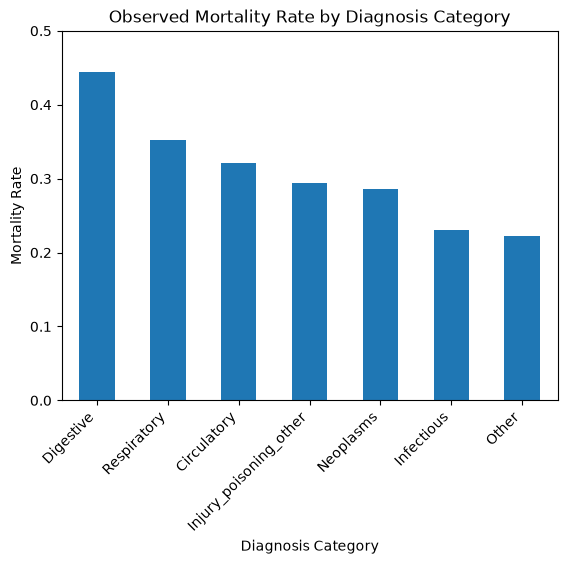

In [23]:
mortality_by_diagnosis = (
    final_data.groupby("diagnosis_category_model")["hospital_expire_flag"]
    .mean()
    .sort_values(ascending=False)
)

mortality_by_diagnosis.plot(kind="bar")

plt.title("Observed Mortality Rate by Diagnosis Category")
plt.xlabel("Diagnosis Category")
plt.ylabel("Mortality Rate")
plt.xticks(rotation=45, ha="right")
plt.ylim(0, 0.5)

plt.show()

### Observation

Observed mortality varied across diagnosis categories, ranging from approximately 22% to 44%. Digestive diagnoses had the highest observed mortality rate, while the "Other" category had the lowest.

However, each category contained relatively few admissions, meaning that mortality estimates are subject to substantial uncertainty. The differences should therefore be interpreted as exploratory patterns rather than evidence that particular diagnosis categories inherently carry higher mortality risk.

The variation nevertheless suggests that diagnosis category may provide useful clinical context for the predictive model.

## Investigating the effect of the number of diagnoses per admission

In [24]:
final_data.groupby("hospital_expire_flag")["num_diagnoses"].describe()

,count,mean,std,min,25%,50%,75%,max
hospital_expire_flag,,,,,,,,
0,89.0,13.966292,6.814839,3.0,9.0,12.0,18.00,37.0
1,40.0,12.950000,5.629364,4.0,9.0,13.0,16.25,27.0


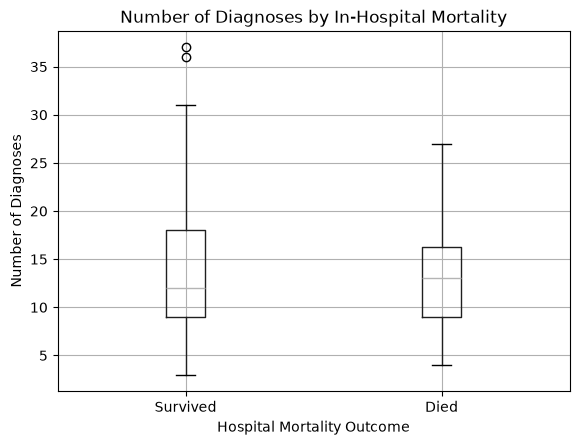

In [25]:
final_data.boxplot(
    column="num_diagnoses",
    by="hospital_expire_flag"
)

plt.title("Number of Diagnoses by In-Hospital Mortality")
plt.suptitle("")
plt.xlabel("Hospital Mortality Outcome")
plt.ylabel("Number of Diagnoses")
plt.xticks(
    ticks=[1, 2],
    labels=["Survived", "Died"]
)

plt.show()

### Observation

The number of diagnosis records showed substantial overlap between admissions resulting in survival and those resulting in death. The median number of diagnoses was 12 among survivors and 13 among deaths, while the mean was slightly higher among survivors (13.97 vs 12.95).

The boxplot similarly showed considerable overlap between the two groups, with no clear separation in the distribution of diagnosis counts. This suggests that the number of recorded diagnoses alone may have limited predictive value for in-hospital mortality, although it may still provide useful information when combined with other clinical features.

## Investigating the effect of lab measurements 

In [26]:
final_data["creatinine"].describe()

count    127.000000
mean       1.335433
std        1.333603
min        0.400000
25%        0.700000
50%        1.000000
75%        1.300000
max       10.500000
Name: creatinine, dtype: float64

In [27]:
final_data.groupby("hospital_expire_flag")["creatinine"].describe()

,count,mean,std,min,25%,50%,75%,max
hospital_expire_flag,,,,,,,,
0,89.0,1.191011,0.933303,0.4,0.7,0.9,1.30,5.8
1,38.0,1.673684,1.953747,0.4,0.8,1.0,1.55,10.5


In [28]:
final_data.groupby("hospital_expire_flag")[
    ["bicarbonate", "calcium", "creatinine", "glucose", "magnesium",
     "potassium", "sodium", "urea_nitrogen", "haematocrit",
     "haemoglobin", "platelet_count", "rdw", "white_blood_cells"]
].median()

,bicarbonate,calcium,creatinine,glucose,magnesium,potassium,sodium,urea_nitrogen,haematocrit,haemoglobin,platelet_count,rdw,white_blood_cells
hospital_expire_flag,,,,,,,,,,,,,
0,25.0,8.3,0.9,118.5,2.1,4.00,140.0,21.0,30.80,10.20,211.0,15.50,10.1
1,23.0,8.2,1.0,142.5,2.0,4.15,138.0,25.5,31.85,10.45,212.5,15.75,10.8


### Observation

Creatinine showed a right-skewed distribution, with a median of 1.0 and a higher mean of 1.34. Most observations were relatively close to the lower end of the range, while a small number of substantially higher measurements increased the mean.

The maximum value of 10.5 was investigated during data cleaning and was found to be associated with a clinically plausible severe case. It was therefore retained rather than treated as a data-entry error.

Median laboratory values showed several differences between admissions resulting in survival and those resulting in in-hospital mortality. 

The mortality group had higher median glucose, creatinine and urea nitrogen, while bicarbonate, sodium and magnesium were slightly lower.

Other measures, including platelet count, showed little difference between groups. 

These observations suggest that several laboratory measurements may contain predictive information, although substantial overlap between groups means that individual laboratory variables are unlikely to be sufficient for mortality prediction.

### Creatinine: 

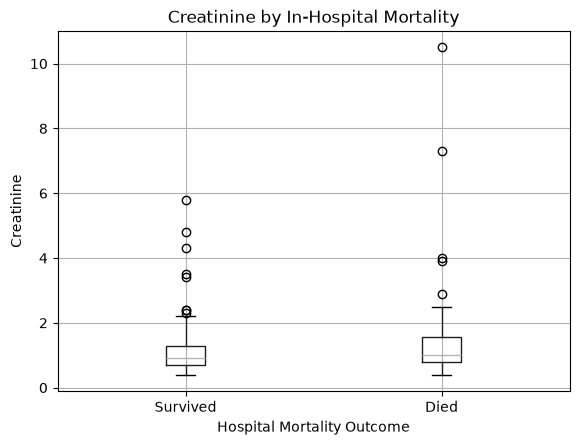

In [29]:
final_data.boxplot(
    column="creatinine",
    by="hospital_expire_flag"
)

plt.title("Creatinine by In-Hospital Mortality")
plt.suptitle("")
plt.xlabel("Hospital Mortality Outcome")
plt.ylabel("Creatinine")
plt.xticks(
    ticks=[1, 2],
    labels=["Survived", "Died"]
)

plt.show()

#### Observations

The distribution of creatinine was generally higher among admissions resulting in in-hospital mortality. 

The mortality group had a slightly higher median and greater upper-range variability, with several extreme observations. 

However, substantial overlap remained between the two groups, indicating that creatinine alone would not be sufficient to distinguish mortality outcomes.

### Glucose: 

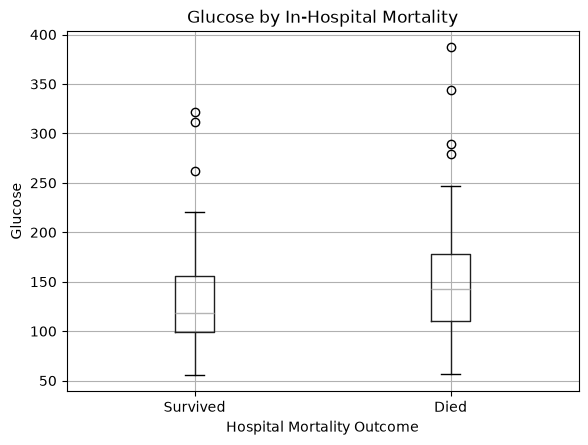

In [30]:
final_data.boxplot(
    column="glucose",
    by="hospital_expire_flag"
)

plt.title("Glucose by In-Hospital Mortality")
plt.suptitle("")
plt.xlabel("Hospital Mortality Outcome")
plt.ylabel("Glucose")
plt.xticks(
    ticks=[1, 2],
    labels=["Survived", "Died"]
)

plt.show()

#### Observations 

Glucose levels were generally higher and more variable among admissions resulting in in-hospital mortality. 

The mortality group had a higher median and greater spread, with several high-value observations. 

However, substantial overlap remained between the two groups, suggesting that glucose alone would not provide a clear separation of mortality outcomes.

### Urea Nitrogen: 

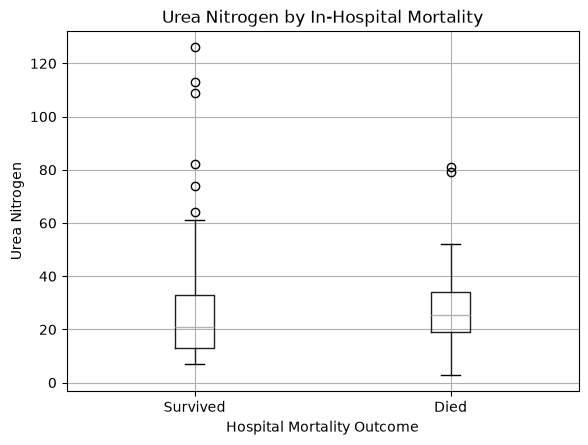

In [31]:
final_data.boxplot(
    column="urea_nitrogen",
    by="hospital_expire_flag"
)

plt.title("Urea Nitrogen by In-Hospital Mortality")
plt.suptitle("")
plt.xlabel("Hospital Mortality Outcome")
plt.ylabel("Urea Nitrogen")
plt.xticks(
    ticks=[1, 2],
    labels=["Survived", "Died"]
)

plt.show()

#### Observations 

Urea nitrogen had a higher median among admissions resulting in in-hospital mortality. 

However, the survived group showed greater variability and contained more extreme high-value observations. T

he distributions overlapped considerably, indicating that urea nitrogen alone would not clearly distinguish mortality outcomes.

## Investigating missing values

In [32]:
final_data.isna().sum().sort_values(ascending=False)

deathtime                   89
language                    48
edouttime                   37
edregtime                   37
marital_status              16
calcium                     14
magnesium                   10
haemoglobin                  4
haematocrit                  4
white_blood_cells            4
rdw                          4
platelet_count               4
urea_nitrogen                3
glucose                      3
potassium                    3
bicarbonate                  3
creatinine                   2
sodium                       2
religion                     1
age_at_admission             0
gender                       0
diagnosis_category_model     0
row_id                       0
has_chartevents_data         0
subject_id                   0
hospital_expire_flag         0
diagnosis                    0
ethnicity                    0
insurance                    0
discharge_location           0
admission_location           0
admission_type               0
dischtim

In [33]:
lab_columns = [
    "bicarbonate",
    "calcium",
    "creatinine",
    "glucose",
    "magnesium",
    "potassium",
    "sodium",
    "urea_nitrogen",
    "haematocrit",
    "haemoglobin",
    "platelet_count",
    "rdw",
    "white_blood_cells"
]

final_data.groupby("hospital_expire_flag")[lab_columns].apply(
    lambda x: x.isna().sum()
)

,bicarbonate,calcium,creatinine,glucose,magnesium,potassium,sodium,urea_nitrogen,haematocrit,haemoglobin,platelet_count,rdw,white_blood_cells
hospital_expire_flag,,,,,,,,,,,,,
0,1,11,0,1,7,1,0,1,2,2,2,2,2
1,2,3,2,2,3,2,2,2,2,2,2,2,2


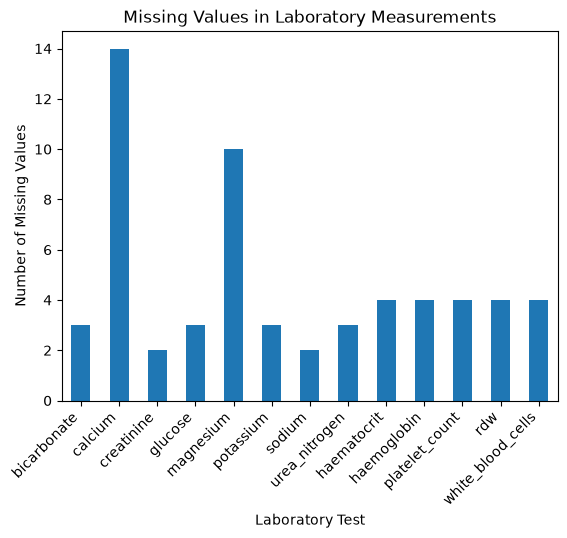

In [34]:
missing_labs = final_data[lab_columns].isna().sum()

missing_labs.plot(kind="bar")

plt.title("Missing Values in Laboratory Measurements")
plt.xlabel("Laboratory Test")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=45, ha="right")

plt.show()

### Observations
Missing laboratory measurements were generally limited and broadly similar between admissions that survived and those resulting in in-hospital mortality. 

Calcium showed the greatest difference in missingness, with 11 missing values among surviving admissions compared with 3 among admissions resulting in death. 

However, the small number of missing observations limits the reliability of comparisons between outcome groups. 

Missingness is therefore unlikely to be a major obstacle, although laboratory variables will require appropriate imputation during model development.

## Correlation analysis

In [35]:
correlation_data = final_data[
    ["age_at_admission", "num_diagnoses"] + lab_columns
]

correlation_matrix = correlation_data.corr()

correlation_matrix

,age_at_admission,num_diagnoses,bicarbonate,calcium,creatinine,glucose,magnesium,potassium,sodium,urea_nitrogen,haematocrit,haemoglobin,platelet_count,rdw,white_blood_cells
age_at_admission,1.000000,-0.012811,0.091824,0.094816,-0.102660,-0.054230,-0.005972,0.185613,-0.018939,0.200713,0.256522,0.182073,0.065733,0.025632,-0.036693
num_diagnoses,-0.012811,1.000000,0.111726,0.003768,0.062970,-0.077433,0.101105,0.018797,0.170910,0.266439,0.036912,-0.042847,-0.079747,0.348349,-0.005277
bicarbonate,0.091824,0.111726,1.000000,0.194135,-0.096912,0.022424,-0.051666,-0.043438,-0.022263,-0.168690,0.138590,0.000308,0.101826,0.081235,-0.252582
calcium,0.094816,0.003768,0.194135,1.000000,0.222885,-0.014181,0.153619,0.143529,-0.152030,0.176918,0.161665,0.204224,0.002212,0.023568,-0.132574
creatinine,-0.102660,0.062970,-0.096912,0.222885,1.000000,0.102230,0.065966,0.079060,-0.145562,0.387392,-0.164713,-0.080185,-0.243314,0.138000,-0.124954
glucose,-0.054230,-0.077433,0.022424,-0.014181,0.102230,1.000000,-0.024135,-0.019412,0.168935,0.021141,0.157217,0.195426,-0.136119,-0.143786,0.200478
magnesium,-0.005972,0.101105,-0.051666,0.153619,0.065966,-0.024135,1.000000,0.093102,0.048874,0.346624,0.059114,0.067202,0.017408,-0.077296,0.044488
potassium,0.185613,0.018797,-0.043438,0.143529,0.079060,-0.019412,0.093102,1.000000,-0.191230,0.185604,0.146005,0.134543,0.138059,0.123689,0.040380
sodium,-0.018939,0.170910,-0.022263,-0.152030,-0.145562,0.168935,0.048874,-0.191230,1.000000,0.100719,0.179443,0.133629,-0.003678,-0.066223,0.127576
urea_nitrogen,0.200713,0.266439,-0.168690,0.176918,0.387392,0.021141,0.346624,0.185604,0.100719,1.000000,0.016997,0.026927,-0.148991,0.196991,-0.021177


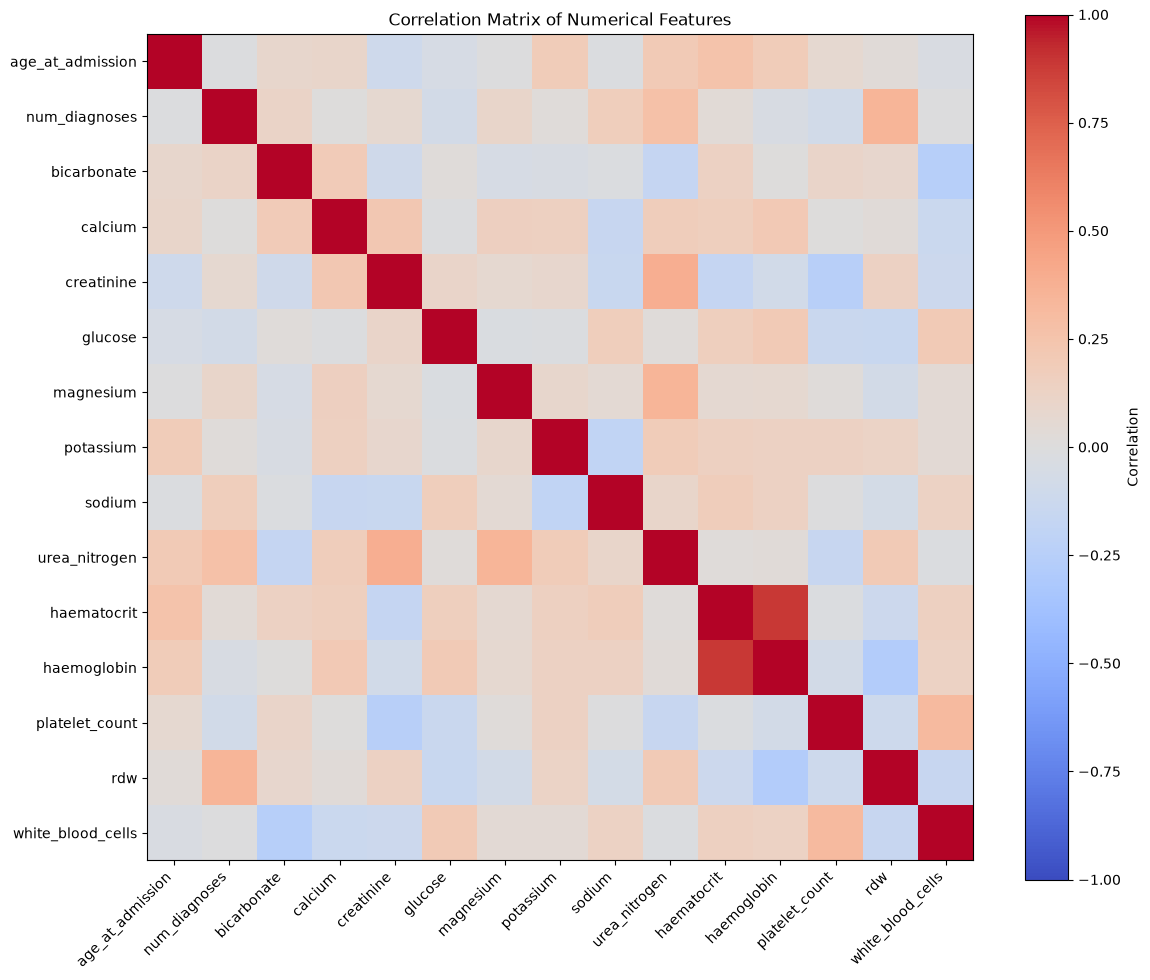

In [36]:
plt.figure(figsize=(12, 10))

plt.imshow(correlation_matrix, cmap="coolwarm", vmin=-1, vmax=1)

plt.colorbar(label="Correlation")

plt.xticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns
)

plt.title("Correlation Matrix of Numerical Features")

plt.tight_layout()
plt.show()

### Observations

Most numerical features showed weak to moderate linear correlations with one another. 

The strongest relationship was between haematocrit and haemoglobin (r = 0.89), indicating substantial redundancy between these two measurements. 

Urea nitrogen and creatinine showed a moderate positive correlation (r = 0.38), while the remaining relationships were comparatively weak. 

The strong correlation between haematocrit and haemoglobin should be considered when interpreting models that are sensitive to multicollinearity.

## EDA Summary

The exploratory analysis identified several characteristics of the dataset that are relevant to subsequent machine learning. The dataset contained 129 hospital admissions, of which 89 resulted in survival to discharge and 40 resulted in in-hospital mortality. The outcome was therefore moderately imbalanced, with mortality occurring in approximately 31% of admissions.

Admissions were predominantly among older adults, with the distribution concentrated towards the upper end of the age range. The concentration of observations at 90 years reflects the de-identification procedures used in MIMIC-III rather than a literal concentration of patients at exactly 90 years of age.

Several demographic and admission characteristics showed substantial imbalance between categories. Emergency admissions accounted for the vast majority of observations, while elective and urgent admissions were represented by very small numbers. Similar limitations were observed for some admission-location and insurance categories. Consequently, differences in mortality rates between these small subgroups should not be interpreted as reliable estimates.

The clinical variables showed some differences between mortality outcomes. In particular, admissions resulting in death generally had higher median creatinine, glucose and urea nitrogen measurements, although considerable overlap remained between the outcome groups. The number of recorded diagnoses showed broadly similar distributions between survivors and non-survivors.

Missing laboratory measurements were generally limited. Calcium and magnesium had the greatest levels of missingness, while most other laboratory variables had only a small number of missing observations. Appropriate imputation will therefore be required during model development.

Correlation analysis identified a strong positive relationship between haematocrit and haemoglobin (r = 0.89), while most other numerical variables showed weak to moderate correlations. This relationship will be considered when interpreting models that are sensitive to multicollinearity.

Overall, the EDA suggests that the dataset contains potentially informative clinical predictors of in-hospital mortality, while also highlighting important limitations associated with the small sample size, outcome imbalance, categorical subgroup sizes and missing laboratory measurements.